<a href="https://colab.research.google.com/github/ojaswip2828/retail-dimensional-model/blob/main/Week5_Dimensional_Model_Window_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 Week 5 Mini Project — Retail Dimensional Model + Window Function Report + CTE MoM Growth

**Stack:** PostgreSQL 16 running *inside* this Colab runtime · Python (`psycopg2`, `pandas`, `matplotlib`)

**Scenario.** An Indian omni-channel retailer (Web / App / Store, 11 cities, 20 SKUs) hands you a **flat order export** — one row per order with the basket crammed into a text column. Your job:

1. **Normalize** the export from *0NF → 1NF → 2NF → 3NF* (OLTP model).
2. Build a **star schema** (dimensional model) for analytics.
3. Answer business questions with **subqueries** (scalar, correlated, `EXISTS` / `NOT EXISTS`) and **set operators**.
4. Produce a **window-function report** (`RANK`, `DENSE_RANK`, `LAG`, `LEAD`, `NTILE`, frames).
5. Compute **Month-over-Month growth with CTEs** (incl. a **recursive CTE** month spine).
6. Build subtotals with **`ROLLUP` / `CUBE` / `GROUPING SETS`**.
7. Publish a **view** and a **materialized view** for BI.

| # | Section | Week-5 topics |
|---|---|---|
| 0 | Setup | — |
| 1 | Source data | — |
| 2 | Normalization | 1NF, 2NF, 3NF |
| 3 | Star schema | Dimensional modeling, recursive CTE |
| 4 | Subqueries & set ops | scalar, correlated, EXISTS / NOT EXISTS, UNION / INTERSECT / EXCEPT |
| 5 | Window function report | RANK, DENSE_RANK, ROW_NUMBER, LAG, LEAD, NTILE, ROWS/RANGE frames |
| 6 | CTE MoM growth | chained CTEs, recursive CTE, MoM / YoY |
| 7 | Subtotals | ROLLUP, CUBE, GROUPING SETS, GROUPING() |
| 8 | Views | VIEW, MATERIALIZED VIEW, REFRESH CONCURRENTLY |
| 9 | Executive report | everything combined + charts |
| 10 | Self-test | predict-the-output practice |

> ▶️ **Run:** `Runtime → Run all`. The notebook is idempotent — re-running drops and rebuilds everything.

## 0. Setup — PostgreSQL 16 in Colab

In [1]:
# ⚙️ Install PostgreSQL 16 inside Colab (~60-90 s). MERGE needs PostgreSQL 15+,
# and Colab's default apt repo only ships 14, so we add the official PGDG repo.
!sudo apt-get -qq update > /dev/null
!sudo apt-get -qq install -y curl ca-certificates lsb-release > /dev/null
!sudo install -d /usr/share/postgresql-common/pgdg
!sudo curl -s -o /usr/share/postgresql-common/pgdg/apt.postgresql.org.asc https://www.postgresql.org/media/keys/ACCC4CF8.asc
!sudo sh -c 'echo "deb [signed-by=/usr/share/postgresql-common/pgdg/apt.postgresql.org.asc] https://apt.postgresql.org/pub/repos/apt $(lsb_release -cs)-pgdg main" > /etc/apt/sources.list.d/pgdg.list'
!sudo apt-get -qq update > /dev/null
!sudo DEBIAN_FRONTEND=noninteractive apt-get -qq install -y postgresql-16 > /dev/null
!sudo service postgresql start
!sudo -u postgres psql -q -c "ALTER USER postgres PASSWORD 'postgres';"
!pip -q install psycopg2-binary

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 4.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[ OK ]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 54.8 MB/s eta 0:00:00


In [2]:
import psycopg2, pandas as pd
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

def _connect(db, autocommit=True):
    c = psycopg2.connect(host="localhost", user="postgres", password="postgres", dbname=db)
    c.autocommit = autocommit
    return c

# create the project database once
_admin = _connect("postgres")
with _admin.cursor() as cur:
    cur.execute("SELECT 1 FROM pg_database WHERE datname = 'retail_dw'")
    if not cur.fetchone():
        cur.execute("CREATE DATABASE retail_dw")
_admin.close()

conn = _connect("retail_dw")

def sql(query, params=None, conn=None):
    """Run SQL. Returns a DataFrame when the last statement returns rows, else prints the status."""
    c = conn or globals()["conn"]
    with c.cursor() as cur:
        cur.execute(query, params)
        for n in c.notices:          # RAISE NOTICE output from functions/procedures
            print(n.strip())
        del c.notices[:]
        if cur.description:
            return pd.DataFrame(cur.fetchall(), columns=[d[0] for d in cur.description])
        print(cur.statusmessage)

def explain(query, analyze=True):
    """Print an execution plan (EXPLAIN ANALYZE by default)."""
    opts = "ANALYZE, BUFFERS, COSTS OFF, TIMING ON" if analyze else "COSTS OFF"
    with conn.cursor() as cur:
        cur.execute(f"EXPLAIN ({opts}) " + query)
        print("\n".join(r[0] for r in cur.fetchall()))

sql("SELECT version()")

,version
0,"PostgreSQL 16.15 (Ubuntu 16.15-1.pgdg24.04+2) on x86_64-pc-linux-gnu, compil..."


## 1. Source data — the "flat export"

We generate deterministic data with `setseed()` so results are reproducible:
* 400 customers across 11 cities / 4 regions, with **staggered sign-up dates** (growth), **~25% churners** and a **preferred department**
* 20 products in 6 categories under 3 departments
* 3,500 orders from **Jan 2025 → Jun 2026**
* the basket is packed into one text column: `SKU-05x1;SKU-12x3`  ← this violates 1NF

In [3]:
sql("""
DROP SCHEMA IF EXISTS raw  CASCADE;
DROP SCHEMA IF EXISTS oltp CASCADE;
DROP SCHEMA IF EXISTS dw   CASCADE;
CREATE SCHEMA raw; CREATE SCHEMA oltp; CREATE SCHEMA dw;

-- reference lists used only to generate the export
CREATE TABLE raw.ref_products (sku text, product_name text, category text, department text, unit_price numeric(10,2));
INSERT INTO raw.ref_products VALUES
 ('SKU-01','Smartphone Lite','Phones','Electronics',17999),
 ('SKU-02','Smartphone Pro','Phones','Electronics',69900),
 ('SKU-03','Smartphone Plus','Phones','Electronics',32999),
 ('SKU-04','Laptop 14 Business','Laptops','Electronics',62990),
 ('SKU-05','Laptop Ultra 13','Laptops','Electronics',114900),
 ('SKU-06','Laptop Slim 15','Laptops','Electronics',45990),
 ('SKU-07','Wireless Earbuds','Audio','Electronics',1499),
 ('SKU-08','Noise-Cancelling Headphones','Audio','Electronics',29990),
 ('SKU-09','Bluetooth Speaker','Audio','Electronics',9999),
 ('SKU-10','Pressure Cooker 5L','Kitchen','Home',2499),
 ('SKU-11','Air Fryer','Kitchen','Home',8999),
 ('SKU-12','Glass Tumbler Set','Kitchen','Home',999),
 ('SKU-13','Study Table','Furniture','Home',7499),
 ('SKU-14','Ergonomic Chair','Furniture','Home',12999),
 ('SKU-15','Bookshelf','Furniture','Home',5999),
 ('SKU-16','Men Denim Jacket','Menswear','Fashion',2999),
 ('SKU-17','Men Running Shoes','Menswear','Fashion',4499),
 ('SKU-18','Women Kurta Set','Womenswear','Fashion',1899),
 ('SKU-19','Women Handbag','Womenswear','Fashion',3499),
 ('SKU-20','Women Sneakers','Womenswear','Fashion',3999);

CREATE TABLE raw.ref_cities (city text, state text, region text);
INSERT INTO raw.ref_cities VALUES
 ('Bengaluru','Karnataka','South'),('Chennai','Tamil Nadu','South'),('Hyderabad','Telangana','South'),
 ('Mumbai','Maharashtra','West'),('Pune','Maharashtra','West'),('Ahmedabad','Gujarat','West'),
 ('Delhi','Delhi','North'),('Jaipur','Rajasthan','North'),('Lucknow','Uttar Pradesh','North'),
 ('Kolkata','West Bengal','East'),('Bhubaneswar','Odisha','East');

SELECT setseed(0.42);

CREATE TABLE raw.orders_flat AS
WITH cities AS (SELECT array_agg(city ORDER BY city) AS a FROM raw.ref_cities),
customers AS MATERIALIZED (
    SELECT g AS cust_no,
           'Customer ' || lpad(g::text, 3, '0')                AS customer_name,
           'cust' || lpad(g::text, 3, '0') || '@example.com'   AS customer_email,
           (SELECT a FROM cities)[1 + floor(random() * 11)::int] AS city,
           DATE '2025-01-01' + floor(power(random(), 0.8) * 480)::int AS signup_date,  -- more sign-ups later
           random() AS churn_r, random() AS span_r, random() AS pref_r
    FROM generate_series(1, 400) g
),
cust AS MATERIALIZED (
    SELECT *,
           CASE WHEN churn_r < 0.25                                        -- ~25% customers churn
                THEN GREATEST(signup_date, LEAST(signup_date + 45 + floor(span_r * 240)::int, DATE '2026-03-31'))
                ELSE DATE '2026-06-30' END AS active_until,
           CASE WHEN pref_r < 0.4 THEN 0 WHEN pref_r < 0.7 THEN 1 ELSE 2 END AS pref  -- 0=Electronics 1=Home 2=Fashion
    FROM customers
),
orders AS MATERIALIZED (
    SELECT 100000 + g AS order_id,
           1 + floor(random() * 400)::int                          AS cust_no,
           (ARRAY['Web','App','Store'])[1 + floor(random() * 3)::int] AS channel,
           1 + floor(random() * 3)::int                            AS n_items,
           random()                                                AS date_r
    FROM generate_series(1, 3500) g
)
SELECT o.order_id,
       c.signup_date + floor(o.date_r * (c.active_until - c.signup_date + 1))::int AS order_date,
       c.customer_name, c.customer_email, c.city, rc.state, rc.region, o.channel, i.items
FROM orders o
JOIN cust c USING (cust_no)
JOIN raw.ref_cities rc ON rc.city = c.city
CROSS JOIN LATERAL (
    SELECT string_agg(sku || 'x' || q, ';' ORDER BY sku) AS items
    FROM (SELECT sku, sum(qty) AS q
          FROM (SELECT CASE WHEN random() < 0.7 THEN          -- 70% of items from the preferred department
                         CASE c.pref WHEN 0 THEN 'SKU-' || lpad((1  + floor(random() * 9))::text, 2, '0')
                                     WHEN 1 THEN 'SKU-' || lpad((10 + floor(random() * 6))::text, 2, '0')
                                     ELSE        'SKU-' || lpad((16 + floor(random() * 5))::text, 2, '0') END
                       ELSE 'SKU-' || lpad((1 + floor(random() * 20))::text, 2, '0') END AS sku,
                       1 + floor(random() * 2)::int AS qty
                FROM generate_series(1, o.n_items + 0 * c.cust_no) g) picks
          GROUP BY sku) basket
) i;
""")
sql("SELECT * FROM raw.orders_flat ORDER BY order_id LIMIT 8")

NOTICE:  schema "raw" does not exist, skipping
NOTICE:  schema "oltp" does not exist, skipping
NOTICE:  schema "dw" does not exist, skipping
SELECT 3500


,order_id,order_date,customer_name,customer_email,city,state,region,channel,items
0,100001,2026-03-12,Customer 298,cust298@example.com,Bengaluru,Karnataka,South,App,SKU-16x2;SKU-18x1;SKU-19x2
1,100002,2025-12-01,Customer 361,cust361@example.com,Kolkata,West Bengal,East,Web,SKU-16x2
2,100003,2026-05-17,Customer 400,cust400@example.com,Delhi,Delhi,North,Store,SKU-16x2
3,100004,2026-02-23,Customer 222,cust222@example.com,Delhi,Delhi,North,App,SKU-03x2;SKU-06x1;SKU-09x2
4,100005,2026-06-15,Customer 386,cust386@example.com,Bhubaneswar,Odisha,East,Store,SKU-10x2;SKU-13x2
5,100006,2025-04-29,Customer 391,cust391@example.com,Jaipur,Rajasthan,North,Web,SKU-10x2;SKU-15x1
6,100007,2025-12-10,Customer 207,cust207@example.com,Delhi,Delhi,North,Store,SKU-06x2;SKU-20x4
7,100008,2026-03-09,Customer 263,cust263@example.com,Hyderabad,Telangana,South,Web,SKU-08x2;SKU-12x1;SKU-14x1


In [4]:
sql("""
SELECT count(*) AS orders, min(order_date) AS first_order, max(order_date) AS last_order,
       count(DISTINCT customer_email) AS customers
FROM raw.orders_flat
""")

,orders,first_order,last_order,customers
0,3500,2025-01-05,2026-06-30,400


## 2. Normalization: 0NF → 1NF → 2NF → 3NF

| Form | Rule | Violation in our export | Fix |
|---|---|---|---|
| **1NF** | atomic values, no repeating groups | `items = 'SKU-05x1;SKU-12x3'` | one row per (order, product) |
| **2NF** | 1NF + no *partial* dependency on part of a composite key | key is `(order_id, sku)` but `order_date`, `customer_*` depend only on `order_id`; `product_name`, `unit_price` only on `sku` | split into `orders`, `products`, `order_items` |
| **3NF** | 2NF + no *transitive* dependency | `order_id → customer_email → customer_name, city → state → region`; `category → department` | split into `customers`, `cities`, `states`, `regions`, `categories` |

### 2.1 First Normal Form — explode the basket

In [5]:
sql("""
CREATE TABLE raw.order_lines_1nf AS
SELECT f.order_id, f.order_date, f.customer_name, f.customer_email, f.city, f.state, f.region, f.channel,
       split_part(item, 'x', 1)       AS sku,
       split_part(item, 'x', 2)::int  AS qty,
       p.product_name, p.category, p.department, p.unit_price
FROM raw.orders_flat f
CROSS JOIN LATERAL unnest(string_to_array(f.items, ';')) AS item
JOIN raw.ref_products p ON p.sku = split_part(item, 'x', 1);

ALTER TABLE raw.order_lines_1nf ADD PRIMARY KEY (order_id, sku);   -- composite key now possible
""")
sql("SELECT * FROM raw.order_lines_1nf ORDER BY order_id, sku LIMIT 6")

ALTER TABLE


,order_id,order_date,customer_name,customer_email,city,state,region,channel,sku,qty,product_name,category,department,unit_price
0,100001,2026-03-12,Customer 298,cust298@example.com,Bengaluru,Karnataka,South,App,SKU-16,2,Men Denim Jacket,Menswear,Fashion,2999.00
1,100001,2026-03-12,Customer 298,cust298@example.com,Bengaluru,Karnataka,South,App,SKU-18,1,Women Kurta Set,Womenswear,Fashion,1899.00
2,100001,2026-03-12,Customer 298,cust298@example.com,Bengaluru,Karnataka,South,App,SKU-19,2,Women Handbag,Womenswear,Fashion,3499.00
3,100002,2025-12-01,Customer 361,cust361@example.com,Kolkata,West Bengal,East,Web,SKU-16,2,Men Denim Jacket,Menswear,Fashion,2999.00
4,100003,2026-05-17,Customer 400,cust400@example.com,Delhi,Delhi,North,Store,SKU-16,2,Men Denim Jacket,Menswear,Fashion,2999.00
5,100004,2026-02-23,Customer 222,cust222@example.com,Delhi,Delhi,North,App,SKU-03,2,Smartphone Plus,Phones,Electronics,32999.00


### 2.2 Proving the functional dependencies before we split

A dependency `X → Y` holds if every `X` maps to exactly one `Y`. Zero rows returned = dependency holds = safe to split.

In [6]:
sql("""
SELECT 'order_id -> order_date, customer_email, channel' AS dependency, count(*) AS violations FROM (
    SELECT order_id FROM raw.order_lines_1nf GROUP BY order_id
    HAVING count(DISTINCT (order_date, customer_email, channel)) > 1) x
UNION ALL
SELECT 'sku -> product_name, unit_price', count(*) FROM (
    SELECT sku FROM raw.order_lines_1nf GROUP BY sku
    HAVING count(DISTINCT (product_name, unit_price)) > 1) x
UNION ALL
SELECT 'customer_email -> customer_name, city', count(*) FROM (
    SELECT customer_email FROM raw.order_lines_1nf GROUP BY customer_email
    HAVING count(DISTINCT (customer_name, city)) > 1) x
UNION ALL
SELECT 'city -> state -> region', count(*) FROM (
    SELECT city FROM raw.order_lines_1nf GROUP BY city
    HAVING count(DISTINCT (state, region)) > 1) x
UNION ALL
SELECT 'category -> department', count(*) FROM (
    SELECT category FROM raw.order_lines_1nf GROUP BY category
    HAVING count(DISTINCT department) > 1) x
""")

,dependency,violations
0,"order_id -> order_date, customer_email, channel",0
1,category -> department,0
2,city -> state -> region,0
3,"sku -> product_name, unit_price",0
4,"customer_email -> customer_name, city",0


How much redundancy does 1NF still carry? Every line repeats the customer's name, city, state, region and the product's name/price:

In [7]:
sql("""
SELECT count(*)                         AS line_rows,
       count(DISTINCT customer_email)   AS distinct_customers,
       count(DISTINCT sku)              AS distinct_products,
       round(count(*)::numeric / count(DISTINCT customer_email), 1) AS times_each_customer_is_repeated
FROM raw.order_lines_1nf
""")

,line_rows,distinct_customers,distinct_products,times_each_customer_is_repeated
0,6536,400,20,16.3


### 2.3 2NF + 3NF — the normalized OLTP schema

```
regions ─< states ─< cities ─< customers ─< orders ─< order_items >─ products >─ categories (self-ref parent_id)
```

In [8]:
sql("""
CREATE TABLE oltp.regions   (region_id   serial PRIMARY KEY, region_name   text UNIQUE NOT NULL);
CREATE TABLE oltp.states    (state_id    serial PRIMARY KEY, state_name    text UNIQUE NOT NULL,
                             region_id   int NOT NULL REFERENCES oltp.regions);
CREATE TABLE oltp.cities    (city_id     serial PRIMARY KEY, city_name     text UNIQUE NOT NULL,
                             state_id    int NOT NULL REFERENCES oltp.states);
CREATE TABLE oltp.customers (customer_id serial PRIMARY KEY, customer_name text NOT NULL,
                             email       text UNIQUE NOT NULL,
                             city_id     int NOT NULL REFERENCES oltp.cities);
CREATE TABLE oltp.categories(category_id serial PRIMARY KEY, category_name text UNIQUE NOT NULL,
                             parent_id   int REFERENCES oltp.categories);          -- hierarchy
CREATE TABLE oltp.products  (product_id  serial PRIMARY KEY, sku text UNIQUE NOT NULL,
                             product_name text NOT NULL,
                             category_id int NOT NULL REFERENCES oltp.categories,
                             list_price  numeric(10,2) NOT NULL);
CREATE TABLE oltp.orders    (order_id    int PRIMARY KEY,
                             customer_id int NOT NULL REFERENCES oltp.customers,
                             order_date  date NOT NULL,
                             channel     text NOT NULL CHECK (channel IN ('Web','App','Store')));
CREATE TABLE oltp.order_items(order_id   int REFERENCES oltp.orders,
                             product_id  int REFERENCES oltp.products,
                             qty         int NOT NULL CHECK (qty > 0),
                             unit_price  numeric(10,2) NOT NULL,   -- price at time of sale (history!)
                             PRIMARY KEY (order_id, product_id));

-- populate top-down so foreign keys resolve
INSERT INTO oltp.regions(region_name)
SELECT DISTINCT region FROM raw.order_lines_1nf ORDER BY 1;

INSERT INTO oltp.states(state_name, region_id)
SELECT DISTINCT l.state, r.region_id FROM raw.order_lines_1nf l
JOIN oltp.regions r ON r.region_name = l.region ORDER BY 1;

INSERT INTO oltp.cities(city_name, state_id)
SELECT DISTINCT l.city, s.state_id FROM raw.order_lines_1nf l
JOIN oltp.states s ON s.state_name = l.state ORDER BY 1;

INSERT INTO oltp.customers(customer_name, email, city_id)
SELECT DISTINCT l.customer_name, l.customer_email, c.city_id FROM raw.order_lines_1nf l
JOIN oltp.cities c ON c.city_name = l.city ORDER BY 2;

INSERT INTO oltp.categories(category_name) VALUES ('All Products');
INSERT INTO oltp.categories(category_name, parent_id)
SELECT DISTINCT department, (SELECT category_id FROM oltp.categories WHERE category_name = 'All Products')
FROM raw.order_lines_1nf ORDER BY 1;
INSERT INTO oltp.categories(category_name, parent_id)
SELECT DISTINCT l.category, c.category_id FROM raw.order_lines_1nf l
JOIN oltp.categories c ON c.category_name = l.department ORDER BY 1;

INSERT INTO oltp.products(sku, product_name, category_id, list_price)
SELECT DISTINCT l.sku, l.product_name, c.category_id, l.unit_price FROM raw.order_lines_1nf l
JOIN oltp.categories c ON c.category_name = l.category ORDER BY 1;

INSERT INTO oltp.orders(order_id, customer_id, order_date, channel)
SELECT DISTINCT l.order_id, c.customer_id, l.order_date, l.channel FROM raw.order_lines_1nf l
JOIN oltp.customers c ON c.email = l.customer_email;

INSERT INTO oltp.order_items(order_id, product_id, qty, unit_price)
SELECT l.order_id, p.product_id, l.qty, l.unit_price FROM raw.order_lines_1nf l
JOIN oltp.products p ON p.sku = l.sku;
""")
sql("""
SELECT 'regions' AS tbl, count(*) FROM oltp.regions   UNION ALL
SELECT 'states',     count(*) FROM oltp.states        UNION ALL
SELECT 'cities',     count(*) FROM oltp.cities        UNION ALL
SELECT 'customers',  count(*) FROM oltp.customers     UNION ALL
SELECT 'categories', count(*) FROM oltp.categories    UNION ALL
SELECT 'products',   count(*) FROM oltp.products      UNION ALL
SELECT 'orders',     count(*) FROM oltp.orders        UNION ALL
SELECT 'order_items',count(*) FROM oltp.order_items
""")

INSERT 0 6536


,tbl,count
0,regions,4
1,states,10
2,cities,11
3,customers,400
4,categories,11
5,products,20
6,orders,3500
7,order_items,6536


**Lossless check** — joining the 3NF tables back must reproduce the 1NF data exactly (`EXCEPT` both ways returns 0):

In [9]:
sql("""
WITH rebuilt AS (
    SELECT o.order_id, o.order_date, cu.customer_name, cu.email AS customer_email, ci.city_name AS city,
           s.state_name AS state, r.region_name AS region, o.channel, p.sku, oi.qty
    FROM oltp.order_items oi
    JOIN oltp.orders o     USING (order_id)
    JOIN oltp.customers cu USING (customer_id)
    JOIN oltp.cities ci    USING (city_id)
    JOIN oltp.states s     USING (state_id)
    JOIN oltp.regions r    USING (region_id)
    JOIN oltp.products p   USING (product_id)
), original AS (
    SELECT order_id, order_date, customer_name, customer_email, city, state, region, channel, sku, qty
    FROM raw.order_lines_1nf
)
SELECT (SELECT count(*) FROM (SELECT * FROM rebuilt  EXCEPT SELECT * FROM original) a) AS only_in_3nf,
       (SELECT count(*) FROM (SELECT * FROM original EXCEPT SELECT * FROM rebuilt)  b) AS only_in_1nf
""")

,only_in_3nf,only_in_1nf
0,0,0


## 3. Dimensional model (star schema)

3NF is great for writes; analysts want **few joins and readable attributes**. We denormalize *on purpose* into a star:

```
                 dim_date
                    │
 dim_customer ── fact_sales ── dim_product
                    │
               dim_channel
```

* **Grain:** one row per order line (order × product).
* **Measures:** `qty`, `unit_price`, `revenue`.
* **Surrogate keys** (`*_key`) decouple the warehouse from source IDs.
* `dim_product` flattens the category tree using a **recursive CTE**.

In [10]:
sql("""
-- Date dimension: one row per calendar day
CREATE TABLE dw.dim_date AS
SELECT to_char(d, 'YYYYMMDD')::int        AS date_key,
       d::date                            AS full_date,
       extract(year    FROM d)::int       AS year,
       extract(quarter FROM d)::int       AS quarter,
       extract(month   FROM d)::int       AS month,
       to_char(d, 'Mon')                  AS month_name,
       date_trunc('month', d)::date       AS month_start,
       extract(isodow  FROM d)::int       AS day_of_week,
       to_char(d, 'Dy')                   AS day_name,
       extract(isodow  FROM d) IN (6, 7)  AS is_weekend
FROM generate_series(DATE '2025-01-01', DATE '2026-06-30', INTERVAL '1 day') d;
ALTER TABLE dw.dim_date ADD PRIMARY KEY (date_key);

-- Product dimension: flatten the category hierarchy with a recursive CTE
CREATE TABLE dw.dim_product AS
WITH RECURSIVE cat_path AS (
    SELECT category_id, category_name, parent_id, 1 AS lvl, category_name::text AS path
    FROM oltp.categories WHERE parent_id IS NULL                       -- anchor: root
    UNION ALL
    SELECT c.category_id, c.category_name, c.parent_id, cp.lvl + 1,
           cp.path || ' > ' || c.category_name                          -- recursive step
    FROM oltp.categories c JOIN cat_path cp ON c.parent_id = cp.category_id
)
SELECT row_number() OVER (ORDER BY p.product_id)::int AS product_key,
       p.product_id, p.sku, p.product_name,
       cp.category_name   AS category,
       par.category_name  AS department,
       cp.path            AS category_path,
       p.list_price,
       CASE WHEN p.list_price >= 30000 THEN 'Premium'
            WHEN p.list_price >= 5000  THEN 'Mid'
            ELSE 'Budget' END AS price_band
FROM oltp.products p
JOIN cat_path cp        ON cp.category_id  = p.category_id
JOIN oltp.categories par ON par.category_id = cp.parent_id;
ALTER TABLE dw.dim_product ADD PRIMARY KEY (product_key);

-- Customer dimension: geography denormalized in
CREATE TABLE dw.dim_customer AS
SELECT row_number() OVER (ORDER BY cu.customer_id)::int AS customer_key,
       cu.customer_id, cu.customer_name, cu.email,
       ci.city_name AS city, s.state_name AS state, r.region_name AS region,
       (SELECT min(o.order_date) FROM oltp.orders o WHERE o.customer_id = cu.customer_id) AS first_order_date
FROM oltp.customers cu
JOIN oltp.cities ci USING (city_id)
JOIN oltp.states s  USING (state_id)
JOIN oltp.regions r USING (region_id);
ALTER TABLE dw.dim_customer ADD PRIMARY KEY (customer_key);

-- Channel dimension (tiny, but keeps the fact narrow)
CREATE TABLE dw.dim_channel (channel_key int PRIMARY KEY, channel_name text UNIQUE NOT NULL, is_online boolean NOT NULL);
INSERT INTO dw.dim_channel VALUES (1,'Web',true),(2,'App',true),(3,'Store',false);

-- Fact table
CREATE TABLE dw.fact_sales (
    sales_key    bigserial PRIMARY KEY,
    date_key     int NOT NULL REFERENCES dw.dim_date,
    customer_key int NOT NULL REFERENCES dw.dim_customer,
    product_key  int NOT NULL REFERENCES dw.dim_product,
    channel_key  int NOT NULL REFERENCES dw.dim_channel,
    order_id     int NOT NULL,          -- degenerate dimension
    qty          int NOT NULL,
    unit_price   numeric(10,2) NOT NULL,
    revenue      numeric(12,2) NOT NULL
);

INSERT INTO dw.fact_sales (date_key, customer_key, product_key, channel_key, order_id, qty, unit_price, revenue)
SELECT to_char(o.order_date, 'YYYYMMDD')::int, dc.customer_key, dp.product_key, ch.channel_key,
       o.order_id, oi.qty, oi.unit_price, oi.qty * oi.unit_price
FROM oltp.order_items oi
JOIN oltp.orders o        USING (order_id)
JOIN dw.dim_customer dc   ON dc.customer_id = o.customer_id
JOIN dw.dim_product dp    ON dp.product_id  = oi.product_id
JOIN dw.dim_channel ch    ON ch.channel_name = o.channel;

CREATE INDEX ON dw.fact_sales (date_key);
CREATE INDEX ON dw.fact_sales (customer_key);
CREATE INDEX ON dw.fact_sales (product_key);
ANALYZE;
""")
sql("SELECT product_key, sku, product_name, category, department, category_path, price_band FROM dw.dim_product ORDER BY product_key LIMIT 8")

ANALYZE


,product_key,sku,product_name,category,department,category_path,price_band
0,1,SKU-01,Smartphone Lite,Phones,Electronics,All Products > Electronics > Phones,Mid
1,2,SKU-02,Smartphone Pro,Phones,Electronics,All Products > Electronics > Phones,Premium
2,3,SKU-03,Smartphone Plus,Phones,Electronics,All Products > Electronics > Phones,Premium
3,4,SKU-04,Laptop 14 Business,Laptops,Electronics,All Products > Electronics > Laptops,Premium
4,5,SKU-05,Laptop Ultra 13,Laptops,Electronics,All Products > Electronics > Laptops,Premium
5,6,SKU-06,Laptop Slim 15,Laptops,Electronics,All Products > Electronics > Laptops,Premium
6,7,SKU-07,Wireless Earbuds,Audio,Electronics,All Products > Electronics > Audio,Budget
7,8,SKU-08,Noise-Cancelling Headphones,Audio,Electronics,All Products > Electronics > Audio,Mid


In [11]:
# Typical star query: one hop from fact to each dimension
sql("""
SELECT p.department, c.region, round(sum(f.revenue) / 1e5, 2) AS revenue_lakh
FROM dw.fact_sales f
JOIN dw.dim_product  p USING (product_key)
JOIN dw.dim_customer c USING (customer_key)
GROUP BY p.department, c.region
ORDER BY p.department, revenue_lakh DESC
""")

,department,region,revenue_lakh
0,Electronics,West,581.30
1,Electronics,North,507.11
2,Electronics,South,501.42
3,Electronics,East,327.97
4,Fashion,West,31.17
5,Fashion,North,26.85
6,Fashion,South,26.60
7,Fashion,East,17.48
8,Home,North,57.56
9,Home,West,53.35


## 4. Subqueries & set operators

### 4.1 Scalar subquery — each product vs. the average product
A scalar subquery returns exactly **one row, one column** and can be used anywhere a value can.

In [12]:
sql("""
SELECT p.product_name, p.department,
       sum(f.revenue) AS revenue,
       round(sum(f.revenue) /
             (SELECT sum(revenue) / count(DISTINCT product_key) FROM dw.fact_sales), 2) AS x_avg_product
FROM dw.fact_sales f JOIN dw.dim_product p USING (product_key)
GROUP BY p.product_name, p.department
ORDER BY revenue DESC
""")

,product_name,department,revenue,x_avg_product
0,Laptop Ultra 13,Electronics,60322500.00,5.45
1,Laptop 14 Business,Electronics,32376860.00,2.93
2,Smartphone Pro,Electronics,31594800.00,2.86
3,Laptop Slim 15,Electronics,21385350.00,1.93
4,Smartphone Plus,Electronics,16829490.00,1.52
5,Noise-Cancelling Headphones,Electronics,15354880.00,1.39
6,Smartphone Lite,Electronics,9053497.00,0.82
7,Ergonomic Chair,Home,6291516.00,0.57
8,Air Fryer,Home,4742473.00,0.43
9,Bluetooth Speaker,Electronics,4119588.00,0.37


### 4.2 Correlated subquery — "unusually large" orders
The inner query references the outer row (`o.customer_key`), so it is re-evaluated **per outer row**.

In [13]:
sql("""
WITH order_totals AS (
    SELECT customer_key, order_id, sum(revenue) AS order_value
    FROM dw.fact_sales GROUP BY customer_key, order_id
)
SELECT c.customer_name, o.order_id, o.order_value,
       round((SELECT avg(o2.order_value) FROM order_totals o2
              WHERE o2.customer_key = o.customer_key), 0) AS customer_avg
FROM order_totals o JOIN dw.dim_customer c USING (customer_key)
WHERE o.order_value > 3 * (SELECT avg(o2.order_value) FROM order_totals o2
                           WHERE o2.customer_key = o.customer_key)       -- correlated
ORDER BY o.order_value DESC
LIMIT 10
""")

,customer_name,order_id,order_value,customer_avg
0,Customer 272,102120,472599.00,153742
1,Customer 147,101849,469599.00,134419
2,Customer 191,101119,415760.00,119679
3,Customer 212,102474,404680.00,122491
4,Customer 308,101898,404680.00,104857
5,Customer 357,101184,369600.00,100546
6,Customer 271,100543,367770.00,91304
7,Customer 040,101160,356698.00,91135
8,Customer 230,100220,352770.00,88518
9,Customer 232,100237,332699.00,90941


### 4.3 `EXISTS` / `NOT EXISTS`
**(a)** Customers who bought a *Premium* product but **never** anything from *Fashion*:

In [14]:
sql("""
SELECT c.customer_name, c.city
FROM dw.dim_customer c
WHERE EXISTS (SELECT 1 FROM dw.fact_sales f JOIN dw.dim_product p USING (product_key)
              WHERE f.customer_key = c.customer_key AND p.price_band = 'Premium')
  AND NOT EXISTS (SELECT 1 FROM dw.fact_sales f JOIN dw.dim_product p USING (product_key)
                  WHERE f.customer_key = c.customer_key AND p.department = 'Fashion')
ORDER BY c.customer_name
""")

,customer_name,city
0,Customer 003,Bengaluru
1,Customer 006,Kolkata
2,Customer 010,Bhubaneswar
3,Customer 017,Bhubaneswar
4,Customer 025,Hyderabad
...,...,...
67,Customer 372,Lucknow
68,Customer 381,Bengaluru
69,Customer 385,Jaipur
70,Customer 387,Ahmedabad


**(b) Relational division with double `NOT EXISTS`** — customers who bought **every** product in the *Home* department.
Read it as: *"there is no Home product that this customer has not bought."*

In [15]:
sql("""
SELECT c.customer_name, c.region
FROM dw.dim_customer c
WHERE NOT EXISTS (
    SELECT 1 FROM dw.dim_product p
    WHERE p.department = 'Home'
      AND NOT EXISTS (SELECT 1 FROM dw.fact_sales f
                      WHERE f.customer_key = c.customer_key AND f.product_key = p.product_key))
ORDER BY c.customer_name
""")

,customer_name,region
0,Customer 001,South
1,Customer 004,North
2,Customer 005,West
3,Customer 016,East
4,Customer 026,West
...,...,...
57,Customer 379,North
58,Customer 382,West
59,Customer 386,East
60,Customer 397,South


**(c) Churn risk** — customers who ordered in 2025 but have **no order in Q2-2026**:

In [16]:
sql("""
SELECT c.customer_name, c.city, max(d.full_date) AS last_order
FROM dw.dim_customer c
JOIN dw.fact_sales f USING (customer_key)
JOIN dw.dim_date d   USING (date_key)
WHERE NOT EXISTS (SELECT 1 FROM dw.fact_sales f2 JOIN dw.dim_date d2 USING (date_key)
                  WHERE f2.customer_key = c.customer_key
                    AND d2.full_date BETWEEN '2026-04-01' AND '2026-06-30')
GROUP BY c.customer_name, c.city
ORDER BY last_order
""")

,customer_name,city,last_order
0,Customer 009,Pune,2025-03-20
1,Customer 339,Jaipur,2025-04-13
2,Customer 312,Jaipur,2025-04-16
3,Customer 089,Hyderabad,2025-05-01
4,Customer 391,Jaipur,2025-05-13
...,...,...,...
113,Customer 054,Chennai,2026-03-30
114,Customer 100,Pune,2026-03-31
115,Customer 319,Kolkata,2026-03-31
116,Customer 392,Pune,2026-03-31


### 4.4 `UNION` / `UNION ALL` / `INTERSECT` / `EXCEPT` — cohort retention
`UNION` removes duplicates, `UNION ALL` keeps them. `INTERSECT` = in both, `EXCEPT` = in first but not second.

In [17]:
sql("""
WITH h1_2025 AS (SELECT DISTINCT f.customer_key FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key)
                 WHERE d.year = 2025 AND d.quarter <= 2),
     h1_2026 AS (SELECT DISTINCT f.customer_key FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key)
                 WHERE d.year = 2026 AND d.quarter <= 2)
SELECT 'H1-2025 customers'                AS metric, count(*) FROM h1_2025 UNION ALL
SELECT 'H1-2026 customers',                         count(*) FROM h1_2026 UNION ALL
SELECT 'UNION ALL  (with duplicates)',              count(*) FROM (SELECT * FROM h1_2025 UNION ALL SELECT * FROM h1_2026) x UNION ALL
SELECT 'UNION      (either period)',                count(*) FROM (SELECT * FROM h1_2025 UNION     SELECT * FROM h1_2026) x UNION ALL
SELECT 'INTERSECT  (retained)',                     count(*) FROM (SELECT * FROM h1_2025 INTERSECT SELECT * FROM h1_2026) x UNION ALL
SELECT 'EXCEPT     (lost: 2025 not 2026)',          count(*) FROM (SELECT * FROM h1_2025 EXCEPT    SELECT * FROM h1_2026) x UNION ALL
SELECT 'EXCEPT     (new: 2026 not 2025)',           count(*) FROM (SELECT * FROM h1_2026 EXCEPT    SELECT * FROM h1_2025) x
""")

,metric,count
0,H1-2025 customers,83
1,H1-2026 customers,352
2,UNION ALL (with duplicates),435
3,UNION (either period),384
4,INTERSECT (retained),51
5,EXCEPT (lost: 2025 not 2026),32
6,EXCEPT (new: 2026 not 2025),301


## 5. Window function report

Window functions compute across related rows **without collapsing them** (unlike `GROUP BY`).

```
fn(...) OVER (PARTITION BY ... ORDER BY ... [ROWS | RANGE BETWEEN ... AND ...])
```

### 5.1 `ROW_NUMBER` vs `RANK` vs `DENSE_RANK` — see how ties behave
Ranking customers by **number of orders** produces lots of ties:

In [18]:
sql("""
WITH cust_orders AS (
    SELECT c.region, c.customer_name, count(DISTINCT f.order_id) AS orders
    FROM dw.fact_sales f JOIN dw.dim_customer c USING (customer_key)
    GROUP BY c.region, c.customer_name
)
SELECT region, customer_name, orders,
       ROW_NUMBER() OVER w AS row_number,   -- always unique
       RANK()       OVER w AS rank,         -- ties share, then gap   (1,1,3)
       DENSE_RANK() OVER w AS dense_rank    -- ties share, no gap     (1,1,2)
FROM cust_orders
WINDOW w AS (PARTITION BY region ORDER BY orders DESC)
ORDER BY region, orders DESC
LIMIT 15
""")

,region,customer_name,orders,row_number,rank,dense_rank
0,East,Customer 343,15,1,1,1
1,East,Customer 323,15,2,1,1
2,East,Customer 152,15,3,1,1
3,East,Customer 289,15,4,1,1
4,East,Customer 122,15,5,1,1
5,East,Customer 016,15,6,1,1
6,East,Customer 052,14,7,7,2
7,East,Customer 125,14,8,7,2
8,East,Customer 057,14,9,7,2
9,East,Customer 103,13,10,10,3


### 5.2 Top-3 products per department (classic interview pattern: rank in a CTE, filter outside)

In [19]:
sql("""
WITH product_rev AS (
    SELECT p.department, p.product_name, sum(f.revenue) AS revenue,
           DENSE_RANK() OVER (PARTITION BY p.department ORDER BY sum(f.revenue) DESC) AS rnk
    FROM dw.fact_sales f JOIN dw.dim_product p USING (product_key)
    GROUP BY p.department, p.product_name
)
SELECT department, rnk, product_name, revenue,
       round(100.0 * revenue / sum(revenue) OVER (PARTITION BY department), 1) AS pct_of_dept
FROM product_rev
WHERE rnk <= 3
ORDER BY department, rnk
""")

,department,rnk,product_name,revenue,pct_of_dept
0,Electronics,1,Laptop Ultra 13,60322500.00,48.5
1,Electronics,2,Laptop 14 Business,32376860.00,26.0
2,Electronics,3,Smartphone Pro,31594800.00,25.4
3,Fashion,1,Men Running Shoes,2721895.00,37.0
4,Fashion,2,Women Sneakers,2651337.00,36.0
5,Fashion,3,Women Handbag,1987432.00,27.0
6,Home,1,Ergonomic Chair,6291516.00,43.2
7,Home,2,Air Fryer,4742473.00,32.6
8,Home,3,Study Table,3524530.00,24.2


### 5.3 `LAG` / `LEAD` — previous & next month per department

In [20]:
sql("""
WITH m AS (
    SELECT d.month_start, p.department, sum(f.revenue) AS revenue
    FROM dw.fact_sales f
    JOIN dw.dim_date d    USING (date_key)
    JOIN dw.dim_product p USING (product_key)
    GROUP BY d.month_start, p.department
)
SELECT department, month_start, revenue,
       LAG(revenue)  OVER w AS prev_month,
       LEAD(revenue) OVER w AS next_month,
       revenue - LAG(revenue) OVER w AS delta_vs_prev
FROM m
WINDOW w AS (PARTITION BY department ORDER BY month_start)
ORDER BY department, month_start
LIMIT 12
""")

,department,month_start,revenue,prev_month,next_month,delta_vs_prev
0,Electronics,2025-01-01,471328.00,None,1595965.00,None
1,Electronics,2025-02-01,1595965.00,471328.00,2762354.00,1124637.00
2,Electronics,2025-03-01,2762354.00,1595965.00,3710497.00,1166389.00
3,Electronics,2025-04-01,3710497.00,2762354.00,4187057.00,948143.00
4,Electronics,2025-05-01,4187057.00,3710497.00,4070509.00,476560.00
5,Electronics,2025-06-01,4070509.00,4187057.00,6060021.00,-116548.00
6,Electronics,2025-07-01,6060021.00,4070509.00,8113688.00,1989512.00
7,Electronics,2025-08-01,8113688.00,6060021.00,8386899.00,2053667.00
8,Electronics,2025-09-01,8386899.00,8113688.00,10545601.00,273211.00
9,Electronics,2025-10-01,10545601.00,8386899.00,10061472.00,2158702.00


### 5.4 Frames — running total, 3-month moving average, 7-day rolling window

* `ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW` → running total
* `ROWS BETWEEN 2 PRECEDING AND CURRENT ROW` → 3-row moving average (counts **rows**)
* `RANGE BETWEEN INTERVAL '6 days' PRECEDING AND CURRENT ROW` → 7-**calendar-day** window (robust to missing days)

> ⚠️ Default frame with `ORDER BY` is `RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW` — **peers (ties) are included**, a common source of "wrong" running totals.

In [21]:
sql("""
WITH monthly AS (
    SELECT d.month_start, sum(f.revenue) AS revenue
    FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key)
    GROUP BY d.month_start
)
SELECT month_start, revenue,
       sum(revenue) OVER (ORDER BY month_start ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running_total,
       round(avg(revenue) OVER (ORDER BY month_start ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 0) AS moving_avg_3m,
       sum(revenue) OVER (PARTITION BY extract(year FROM month_start) ORDER BY month_start)        AS ytd_revenue
FROM monthly
ORDER BY month_start
""")

,month_start,revenue,running_total,moving_avg_3m,ytd_revenue
0,2025-01-01,524119.00,524119.00,524119,524119.00
1,2025-02-01,1715535.00,2239654.00,1119827,2239654.00
2,2025-03-01,3120982.00,5360636.00,1786879,5360636.00
3,2025-04-01,4433547.00,9794183.00,3090021,9794183.00
4,2025-05-01,4949107.00,14743290.00,4167879,14743290.00
5,2025-06-01,4730871.00,19474161.00,4704508,19474161.00
6,2025-07-01,6993936.00,26468097.00,5557971,26468097.00
7,2025-08-01,9421323.00,35889420.00,7048710,35889420.00
8,2025-09-01,10026276.00,45915696.00,8813845,45915696.00
9,2025-10-01,12113061.00,58028757.00,10520220,58028757.00


In [22]:
sql("""
WITH daily AS (
    SELECT d.full_date, sum(f.revenue) AS revenue
    FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key)
    WHERE d.full_date BETWEEN '2026-06-01' AND '2026-06-30'
    GROUP BY d.full_date
)
SELECT full_date, revenue,
       sum(revenue) OVER (ORDER BY full_date ROWS  BETWEEN 6 PRECEDING AND CURRENT ROW)                  AS last_7_rows,
       sum(revenue) OVER (ORDER BY full_date RANGE BETWEEN INTERVAL '6 days' PRECEDING AND CURRENT ROW)  AS last_7_days
FROM daily
ORDER BY full_date
LIMIT 12
""")

,full_date,revenue,last_7_rows,last_7_days
0,2026-06-01,765002.00,765002.00,765002.00
1,2026-06-02,525272.00,1290274.00,1290274.00
2,2026-06-03,226362.00,1516636.00,1516636.00
3,2026-06-04,492452.00,2009088.00,2009088.00
4,2026-06-05,795974.00,2805062.00,2805062.00
5,2026-06-06,1130690.00,3935752.00,3935752.00
6,2026-06-07,839859.00,4775611.00,4775611.00
7,2026-06-08,480146.00,4490755.00,4490755.00
8,2026-06-09,426635.00,4392118.00,4392118.00
9,2026-06-10,657446.00,4823202.00,4823202.00


### 5.5 `NTILE` — split customers into lifetime-value quartiles and profile each segment

In [23]:
sql("""
WITH ltv AS (
    SELECT customer_key, sum(revenue) AS lifetime_value, count(DISTINCT order_id) AS orders
    FROM dw.fact_sales GROUP BY customer_key
), q AS (
    SELECT *, NTILE(4) OVER (ORDER BY lifetime_value DESC) AS quartile FROM ltv
)
SELECT quartile,
       CASE quartile WHEN 1 THEN 'Champions' WHEN 2 THEN 'Loyal' WHEN 3 THEN 'Potential' ELSE 'At risk' END AS segment,
       count(*)                       AS customers,
       round(avg(lifetime_value), 0)  AS avg_ltv,
       round(avg(orders), 1)          AS avg_orders,
       round(100.0 * sum(lifetime_value) / sum(sum(lifetime_value)) OVER (), 1) AS pct_of_total_revenue
FROM q
GROUP BY quartile
ORDER BY quartile
""")

,quartile,segment,customers,avg_ltv,avg_orders,pct_of_total_revenue
0,1,Champions,100,1233334,10.1,55.7
1,2,Loyal,100,577741,8.9,26.1
2,3,Potential,100,282942,8.9,12.8
3,4,At risk,100,118955,7.2,5.4


### 5.6 `LAG` on dates — purchase frequency (days between consecutive orders)

In [24]:
sql("""
WITH orders AS (
    SELECT DISTINCT f.customer_key, f.order_id, d.full_date
    FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key)
), gaps AS (
    SELECT customer_key, full_date,
           full_date - LAG(full_date) OVER (PARTITION BY customer_key ORDER BY full_date, order_id) AS days_since_prev
    FROM orders
)
SELECT c.customer_name, count(*) AS orders,
       round(avg(days_since_prev), 1) AS avg_days_between_orders,
       max(days_since_prev)           AS longest_gap
FROM gaps g JOIN dw.dim_customer c USING (customer_key)
GROUP BY c.customer_name
ORDER BY avg_days_between_orders
LIMIT 10
""")

,customer_name,orders,avg_days_between_orders,longest_gap
0,Customer 144,4,0.0,0
1,Customer 111,7,0.0,0
2,Customer 103,13,0.0,0
3,Customer 180,13,0.0,0
4,Customer 018,5,0.0,0
5,Customer 319,11,0.1,1
6,Customer 240,8,0.3,1
7,Customer 241,13,0.5,2
8,Customer 392,12,0.5,2
9,Customer 034,10,1.3,6


## 6. CTE-based Month-over-Month growth

### 6.1 Company-level MoM and YoY with chained CTEs
Each CTE is one readable step: **aggregate → add lags → compute growth → label**.

In [25]:
mom = sql("""
WITH monthly AS (                                   -- step 1: aggregate
    SELECT d.month_start,
           sum(f.revenue)             AS revenue,
           count(DISTINCT f.order_id) AS orders
    FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key)
    GROUP BY d.month_start
), lagged AS (                                      -- step 2: bring previous values onto the row
    SELECT *,
           LAG(revenue)     OVER (ORDER BY month_start) AS prev_revenue,
           LAG(revenue, 12) OVER (ORDER BY month_start) AS revenue_last_year
    FROM monthly
), growth AS (                                      -- step 3: growth %
    SELECT *,
           round(100.0 * (revenue - prev_revenue)      / NULLIF(prev_revenue, 0), 1)      AS mom_pct,
           round(100.0 * (revenue - revenue_last_year) / NULLIF(revenue_last_year, 0), 1) AS yoy_pct,
           round(revenue / orders, 0)                                                     AS avg_order_value
    FROM lagged
)
SELECT month_start, revenue, prev_revenue, mom_pct, yoy_pct, orders, avg_order_value,
       CASE WHEN mom_pct IS NULL THEN '—'
            WHEN mom_pct >= 10   THEN '🚀 strong growth'
            WHEN mom_pct >= 0    THEN '📈 growth'
            WHEN mom_pct > -10   THEN '📉 dip'
            ELSE '🔻 decline' END AS trend
FROM growth
ORDER BY month_start
""")
mom

,month_start,revenue,prev_revenue,mom_pct,yoy_pct,orders,avg_order_value,trend
0,2025-01-01,524119.00,None,None,None,7,74874,—
1,2025-02-01,1715535.00,524119.00,227.3,None,21,81692,🚀 strong growth
2,2025-03-01,3120982.00,1715535.00,81.9,None,46,67847,🚀 strong growth
3,2025-04-01,4433547.00,3120982.00,42.1,None,80,55419,🚀 strong growth
4,2025-05-01,4949107.00,4433547.00,11.6,None,76,65120,🚀 strong growth
5,2025-06-01,4730871.00,4949107.00,-4.4,None,81,58406,📉 dip
6,2025-07-01,6993936.00,4730871.00,47.8,None,104,67249,🚀 strong growth
7,2025-08-01,9421323.00,6993936.00,34.7,None,138,68270,🚀 strong growth
8,2025-09-01,10026276.00,9421323.00,6.4,None,178,56327,📈 growth
9,2025-10-01,12113061.00,10026276.00,20.8,None,194,62438,🚀 strong growth


### 6.2 Recursive CTE month spine — never lose a month with zero sales

`GROUP BY` only returns months that **have** data. If a region-department pair sells nothing in a month, `LAG` would silently compare against the wrong month. A **recursive CTE** generates every month; we `CROSS JOIN` it with all region×department combinations and `LEFT JOIN` the facts.

In [26]:
sql("""
WITH RECURSIVE months AS (
    SELECT DATE '2025-01-01' AS month_start
    UNION ALL
    SELECT (month_start + INTERVAL '1 month')::date FROM months WHERE month_start < DATE '2026-06-01'
), grid AS (
    SELECT m.month_start, r.region, dp.department
    FROM months m
    CROSS JOIN (SELECT DISTINCT region FROM dw.dim_customer) r
    CROSS JOIN (SELECT DISTINCT department FROM dw.dim_product) dp
), actuals AS (
    SELECT d.month_start, c.region, p.department, sum(f.revenue) AS revenue
    FROM dw.fact_sales f
    JOIN dw.dim_date d     USING (date_key)
    JOIN dw.dim_customer c USING (customer_key)
    JOIN dw.dim_product p  USING (product_key)
    GROUP BY 1, 2, 3
), filled AS (
    SELECT g.*, COALESCE(a.revenue, 0) AS revenue
    FROM grid g LEFT JOIN actuals a USING (month_start, region, department)
)
SELECT region, department, month_start, revenue,
       LAG(revenue) OVER (PARTITION BY region, department ORDER BY month_start) AS prev_revenue,
       round(100.0 * (revenue - LAG(revenue) OVER (PARTITION BY region, department ORDER BY month_start))
             / NULLIF(LAG(revenue) OVER (PARTITION BY region, department ORDER BY month_start), 0), 1) AS mom_pct
FROM filled
WHERE region = 'East' AND department = 'Electronics'
ORDER BY month_start
""")

,region,department,month_start,revenue,prev_revenue,mom_pct
0,East,Electronics,2025-01-01,344850.00,None,None
1,East,Electronics,2025-02-01,283947.00,344850.00,-17.7
2,East,Electronics,2025-03-01,659637.00,283947.00,132.3
3,East,Electronics,2025-04-01,692570.00,659637.00,5.0
4,East,Electronics,2025-05-01,288957.00,692570.00,-58.3
5,East,Electronics,2025-06-01,1136886.00,288957.00,293.4
6,East,Electronics,2025-07-01,1139449.00,1136886.00,0.2
7,East,Electronics,2025-08-01,1373277.00,1139449.00,20.5
8,East,Electronics,2025-09-01,1241321.00,1373277.00,-9.6
9,East,Electronics,2025-10-01,1179440.00,1241321.00,-5.0


In [27]:
# How many region × department × month cells had ZERO sales (would have been missing without the spine)?
sql("""
WITH RECURSIVE months AS (
    SELECT DATE '2025-01-01' AS m UNION ALL
    SELECT (m + INTERVAL '1 month')::date FROM months WHERE m < DATE '2026-06-01'
)
SELECT count(*) FILTER (WHERE s.revenue IS NULL) AS empty_cells, count(*) AS total_cells
FROM months
CROSS JOIN (SELECT DISTINCT region FROM dw.dim_customer) r
CROSS JOIN (SELECT DISTINCT department FROM dw.dim_product) p
LEFT JOIN (
    SELECT d.month_start, c.region, pr.department, sum(f.revenue) AS revenue
    FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key)
    JOIN dw.dim_customer c USING (customer_key) JOIN dw.dim_product pr USING (product_key)
    GROUP BY 1, 2, 3
) s ON s.month_start = months.m AND s.region = r.region AND s.department = p.department
""")

,empty_cells,total_cells
0,8,216


### 6.3 Best and worst growth month for each department

In [28]:
sql("""
WITH m AS (
    SELECT p.department, d.month_start, sum(f.revenue) AS revenue
    FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_product p USING (product_key)
    GROUP BY 1, 2
), g AS (
    SELECT *, round(100.0 * (revenue - LAG(revenue) OVER w) / NULLIF(LAG(revenue) OVER w, 0), 1) AS mom_pct
    FROM m WINDOW w AS (PARTITION BY department ORDER BY month_start)
), ranked AS (
    SELECT *, RANK() OVER (PARTITION BY department ORDER BY mom_pct DESC) AS best,
              RANK() OVER (PARTITION BY department ORDER BY mom_pct ASC)  AS worst
    FROM g WHERE mom_pct IS NOT NULL
)
SELECT department,
       max(month_start) FILTER (WHERE best = 1)  AS best_month,  max(mom_pct) AS best_mom_pct,
       max(month_start) FILTER (WHERE worst = 1) AS worst_month, min(mom_pct) AS worst_mom_pct
FROM ranked
GROUP BY department
""")

,department,best_month,best_mom_pct,worst_month,worst_mom_pct
0,Electronics,2025-02-01,238.6,2026-05-01,-21.7
1,Fashion,2025-02-01,314.8,2026-04-01,-29.8
2,Home,2025-03-01,314.3,2025-06-01,-23.7


## 7. Subtotals: `ROLLUP`, `CUBE`, `GROUPING SETS`

| Clause | Groupings produced for `(region, department)` |
|---|---|
| `ROLLUP(region, department)` | (region, department), (region), () — **hierarchical** |
| `CUBE(region, department)` | all 4 combinations incl. (department) alone |
| `GROUPING SETS ((region), (department), ())` | exactly what you list |

`GROUPING(col)` returns **1** when that column was rolled up in the row — use it to label subtotal rows (don't rely on `NULL`, real data can be NULL too).

In [29]:
sql("""
SELECT CASE WHEN GROUPING(c.region) = 1 THEN '★ ALL REGIONS' ELSE c.region END          AS region,
       CASE WHEN GROUPING(p.department) = 1 THEN '— subtotal —' ELSE p.department END   AS department,
       round(sum(f.revenue) / 1e5, 2) AS revenue_lakh,
       GROUPING(c.region, p.department) AS grouping_bits      -- 0 = detail, 1 = region subtotal, 3 = grand total
FROM dw.fact_sales f JOIN dw.dim_customer c USING (customer_key) JOIN dw.dim_product p USING (product_key)
GROUP BY ROLLUP (c.region, p.department)
ORDER BY GROUPING(c.region), c.region, GROUPING(p.department), p.department
""")

,region,department,revenue_lakh,grouping_bits
0,East,Electronics,327.97,0
1,East,Fashion,17.48,0
2,East,Home,38.28,0
3,East,— subtotal —,383.74,1
4,North,Electronics,507.11,0
5,North,Fashion,26.85,0
6,North,Home,57.56,0
7,North,— subtotal —,591.52,1
8,South,Electronics,501.42,0
9,South,Fashion,26.60,0


In [30]:
sql("""
SELECT COALESCE(ch.channel_name, 'ALL') AS channel,
       COALESCE(p.price_band, 'ALL')    AS price_band,
       sum(f.qty)                       AS units,
       round(sum(f.revenue) / 1e5, 2)   AS revenue_lakh
FROM dw.fact_sales f JOIN dw.dim_channel ch USING (channel_key) JOIN dw.dim_product p USING (product_key)
GROUP BY CUBE (ch.channel_name, p.price_band)
ORDER BY GROUPING(ch.channel_name), ch.channel_name, GROUPING(p.price_band), p.price_band
""")

,channel,price_band,units,revenue_lakh
0,App,Budget,1587,43.87
1,App,Mid,1098,143.45
2,App,Premium,789,509.68
3,App,ALL,3474,696.99
4,Store,Budget,1486,42.07
5,Store,Mid,1196,162.89
6,Store,Premium,871,578.11
7,Store,ALL,3553,783.07
8,Web,Budget,1465,41.27
9,Web,Mid,1111,154.34


In [31]:
sql("""
SELECT d.year, d.quarter, c.region, round(sum(f.revenue) / 1e5, 2) AS revenue_lakh
FROM dw.fact_sales f JOIN dw.dim_date d USING (date_key) JOIN dw.dim_customer c USING (customer_key)
GROUP BY GROUPING SETS ((d.year, d.quarter), (d.year, c.region), ())
ORDER BY d.year NULLS LAST, d.quarter NULLS LAST, c.region NULLS LAST
""")

,year,quarter,region,revenue_lakh
0,2025.0,1.0,None,53.61
1,2025.0,2.0,None,141.14
2,2025.0,3.0,None,264.42
3,2025.0,4.0,None,367.82
4,2025.0,NaN,East,136.66
5,2025.0,NaN,North,211.66
6,2025.0,NaN,South,244.28
7,2025.0,NaN,West,234.37
8,2026.0,1.0,None,649.78
9,2026.0,2.0,None,736.22


## 8. Views vs. Materialized Views

| | `VIEW` | `MATERIALIZED VIEW` |
|---|---|---|
| Stores data? | No — saved query, runs every time | Yes — result stored on disk |
| Freshness | Always current | Stale until `REFRESH` |
| Speed | Same as underlying query | Fast reads, can be indexed |
| Use for | Simplifying joins, security (column hiding) | Expensive aggregates for dashboards |

In [32]:
sql("""
CREATE OR REPLACE VIEW dw.v_sales_enriched AS
SELECT f.sales_key, f.order_id, d.full_date, d.month_start, d.year, d.quarter,
       c.customer_name, c.city, c.region, p.product_name, p.category, p.department, p.price_band,
       ch.channel_name AS channel, f.qty, f.unit_price, f.revenue
FROM dw.fact_sales f
JOIN dw.dim_date d     USING (date_key)
JOIN dw.dim_customer c USING (customer_key)
JOIN dw.dim_product p  USING (product_key)
JOIN dw.dim_channel ch USING (channel_key);

DROP MATERIALIZED VIEW IF EXISTS dw.mv_monthly_dept_region;
CREATE MATERIALIZED VIEW dw.mv_monthly_dept_region AS
SELECT month_start, department, region,
       sum(revenue) AS revenue, sum(qty) AS units, count(DISTINCT order_id) AS orders
FROM dw.v_sales_enriched
GROUP BY month_start, department, region
WITH DATA;

-- a UNIQUE index is required for REFRESH ... CONCURRENTLY (readers are not blocked)
CREATE UNIQUE INDEX ux_mv_monthly ON dw.mv_monthly_dept_region (month_start, department, region);
""")
sql("SELECT * FROM dw.mv_monthly_dept_region ORDER BY month_start DESC, revenue DESC LIMIT 6")

NOTICE:  materialized view "mv_monthly_dept_region" does not exist, skipping
CREATE INDEX


,month_start,department,region,revenue,units,orders
0,2026-06-01,Electronics,North,7106041.00,144,60
1,2026-06-01,Electronics,West,5709764.00,136,53
2,2026-06-01,Electronics,South,4882020.00,114,53
3,2026-06-01,Electronics,East,2561825.00,68,26
4,2026-06-01,Home,North,546913.00,87,39
5,2026-06-01,Home,West,543917.00,83,38


**Staleness demo** — insert a test sale: the view sees it immediately, the materialized view only after `REFRESH`.

In [33]:
sql("""
INSERT INTO dw.fact_sales (date_key, customer_key, product_key, channel_key, order_id, qty, unit_price, revenue)
VALUES (20260630, 1, 5, 1, 999999, 1, 114900, 114900);
""")
check = """
SELECT 'view'              AS source, sum(revenue) AS june_2026_revenue FROM dw.v_sales_enriched       WHERE month_start = '2026-06-01'
UNION ALL
SELECT 'materialized view',           sum(revenue)                      FROM dw.mv_monthly_dept_region WHERE month_start = '2026-06-01'
"""
display(sql(check))
sql("REFRESH MATERIALIZED VIEW CONCURRENTLY dw.mv_monthly_dept_region")
display(sql(check))
# clean up the test row
sql("DELETE FROM dw.fact_sales WHERE order_id = 999999")
sql("REFRESH MATERIALIZED VIEW CONCURRENTLY dw.mv_monthly_dept_region")

INSERT 0 1


,source,june_2026_revenue
0,view,23505705.00
1,materialized view,23390805.00


REFRESH MATERIALIZED VIEW


,source,june_2026_revenue
0,view,23505705.00
1,materialized view,23505705.00


DELETE 1
REFRESH MATERIALIZED VIEW


In [34]:
import time
def timed(q, n=20):
    t = time.perf_counter()
    for _ in range(n): sql(q)
    return round((time.perf_counter() - t) / n * 1000, 2)

q_view = "SELECT department, sum(revenue) FROM dw.v_sales_enriched GROUP BY department"
q_mv   = "SELECT department, sum(revenue) FROM dw.mv_monthly_dept_region GROUP BY department"
print(f"view:              {timed(q_view)} ms per query")
print(f"materialized view: {timed(q_mv)} ms per query")

view:              17.83 ms per query
materialized view: 1.5 ms per query


## 9. Executive report — everything together

One query per region and month: revenue, **MoM %**, **3-month moving average**, **regional rank** within the month, and the **#1 product** of the month — built from the materialized view + window functions + CTEs.

In [35]:
report = sql("""
WITH region_month AS (
    SELECT month_start, region, sum(revenue) AS revenue, sum(orders) AS orders
    FROM dw.mv_monthly_dept_region
    GROUP BY month_start, region
), metrics AS (
    SELECT *,
           round(100.0 * (revenue - LAG(revenue) OVER w) / NULLIF(LAG(revenue) OVER w, 0), 1) AS mom_pct,
           round(avg(revenue) OVER (w ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 0)        AS ma_3m,
           RANK() OVER (PARTITION BY month_start ORDER BY revenue DESC)                     AS rank_in_month
    FROM region_month
    WINDOW w AS (PARTITION BY region ORDER BY month_start)
), top_product AS (
    SELECT DISTINCT ON (month_start, region) month_start, region, product_name AS top_product
    FROM (SELECT month_start, region, product_name, sum(revenue) AS rev
          FROM dw.v_sales_enriched GROUP BY 1, 2, 3) x
    ORDER BY month_start, region, rev DESC
)
SELECT m.month_start, m.region, m.revenue, m.mom_pct, m.ma_3m, m.rank_in_month, t.top_product
FROM metrics m JOIN top_product t USING (month_start, region)
ORDER BY m.month_start, m.rank_in_month
""")
report.tail(12)

,month_start,region,revenue,mom_pct,ma_3m,rank_in_month,top_product
59,2026-04-01,North,9580092.00,47.6,6634792,1,Laptop Ultra 13
60,2026-04-01,West,7471623.00,-29.5,7766100,2,Laptop Ultra 13
61,2026-04-01,South,6528619.00,-14.4,6176434,3,Laptop Ultra 13
62,2026-04-01,East,4212394.00,-49.1,5344321,4,Laptop Ultra 13
63,2026-05-01,North,7051240.00,-26.4,7706741,1,Laptop 14 Business
64,2026-05-01,West,6594366.00,-11.7,8222168,2,Laptop Ultra 13
65,2026-05-01,South,4678966.00,-28.3,6277037,3,Laptop Ultra 13
66,2026-05-01,East,4114201.00,-2.3,5535274,4,Laptop Ultra 13
67,2026-06-01,North,7973157.00,13.1,8201496,1,Laptop Ultra 13
68,2026-06-01,West,6715447.00,1.8,6927145,2,Laptop Ultra 13


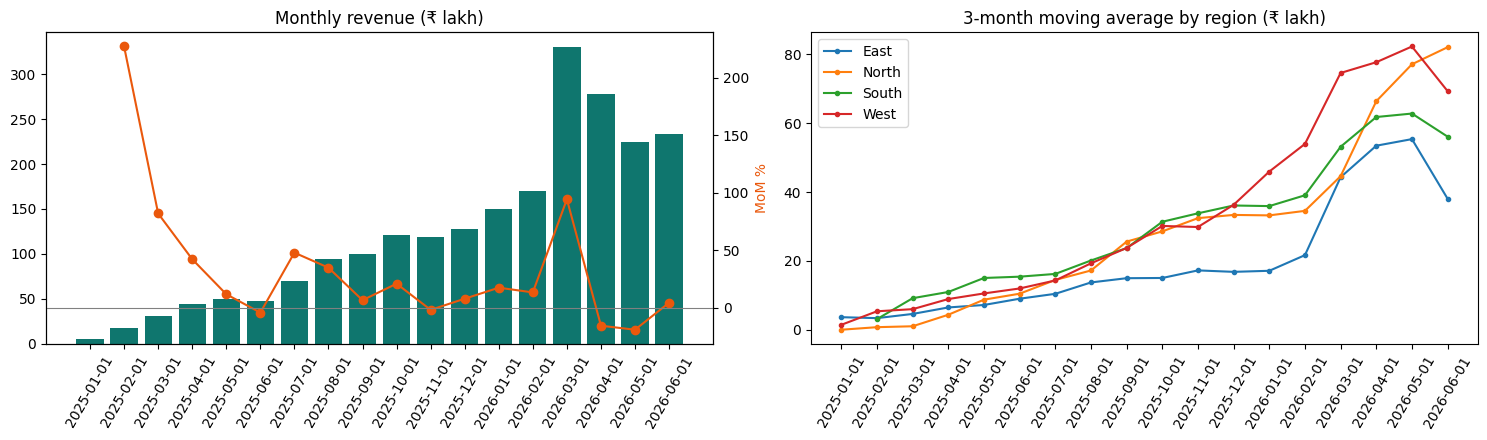

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

m = mom.copy()
m["revenue"] = m["revenue"].astype(float) / 1e5
m["mom_pct"] = m["mom_pct"].astype(float)
axes[0].bar(m["month_start"].astype(str), m["revenue"], color="#0f766e")
axes[0].set_title("Monthly revenue (₹ lakh)")
axes[0].tick_params(axis="x", rotation=60)
ax2 = axes[0].twinx()
ax2.plot(m["month_start"].astype(str), m["mom_pct"], color="#ea580c", marker="o")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("MoM %", color="#ea580c")

r = report.copy()
r["ma_3m"] = r["ma_3m"].astype(float) / 1e5
for region, g in r.groupby("region"):
    axes[1].plot(g["month_start"].astype(str), g["ma_3m"], marker=".", label=region)
axes[1].set_title("3-month moving average by region (₹ lakh)")
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend()
plt.tight_layout()
plt.show()

## 10. Self-test (Week-5 test format)

Try each **before** expanding the answer, then run the cell to verify.

**Q1 — Predict the output.**
```sql
SELECT v, RANK() OVER (ORDER BY v), DENSE_RANK() OVER (ORDER BY v), ROW_NUMBER() OVER (ORDER BY v)
FROM (VALUES (10),(20),(20),(30)) t(v);
```
<details><summary>Answer</summary>

| v | rank | dense_rank | row_number |
|---|---|---|---|
| 10 | 1 | 1 | 1 |
| 20 | 2 | 2 | 2 |
| 20 | 2 | 2 | 3 |
| 30 | **4** | **3** | 4 |
</details>

**Q2 — Predict the output.** (default frame trap)
```sql
SELECT v, sum(v) OVER (ORDER BY v) AS s FROM (VALUES (1),(2),(2),(3)) t(v);
```
<details><summary>Answer</summary>

`1, 5, 5, 8` — the default frame is `RANGE ... CURRENT ROW`, so both `2`s are **peers** and are summed together. Use `ROWS` to get `1, 3, 5, 8`.
</details>

**Q3 — Predict the output.**
```sql
SELECT count(*) FROM (SELECT 1 UNION SELECT 1 UNION ALL SELECT 1) x;
```
<details><summary>Answer</summary>

`2` — set operators are evaluated left-to-right: `(1 UNION 1)` = one row, then `UNION ALL 1` adds a second.
</details>

**Q4 — Write it.** For each region, return the customer with the highest lifetime value (ties included).

In [37]:
display(sql("SELECT v, RANK() OVER (ORDER BY v), DENSE_RANK() OVER (ORDER BY v), ROW_NUMBER() OVER (ORDER BY v) FROM (VALUES (10),(20),(20),(30)) t(v)"))
display(sql("SELECT v, sum(v) OVER (ORDER BY v) AS s_range, sum(v) OVER (ORDER BY v ROWS UNBOUNDED PRECEDING) AS s_rows FROM (VALUES (1),(2),(2),(3)) t(v)"))
display(sql("SELECT count(*) FROM (SELECT 1 UNION SELECT 1 UNION ALL SELECT 1) x"))

,v,rank,dense_rank,row_number
0,10,1,1,1
1,20,2,2,2
2,20,2,2,3
3,30,4,3,4


,v,s_range,s_rows
0,1,1,1
1,2,5,3
2,2,5,5
3,3,8,8


,count
0,2


In [38]:
# Q4 solution
sql("""
WITH ltv AS (
    SELECT c.region, c.customer_name, sum(f.revenue) AS lifetime_value,
           RANK() OVER (PARTITION BY c.region ORDER BY sum(f.revenue) DESC) AS rnk
    FROM dw.fact_sales f JOIN dw.dim_customer c USING (customer_key)
    GROUP BY c.region, c.customer_name
)
SELECT region, customer_name, lifetime_value FROM ltv WHERE rnk = 1 ORDER BY lifetime_value DESC
""")

,region,customer_name,lifetime_value
0,South,Customer 164,2210454.00
1,North,Customer 180,2138063.00
2,West,Customer 060,1914296.00
3,East,Customer 323,1816865.00


---
### ✅ What this project demonstrates
* Normalizing a messy export to **3NF** and proving functional dependencies with SQL
* Designing a **star schema** with surrogate keys, a date dimension and a flattened hierarchy
* Answering business questions with **correlated / EXISTS / relational-division** subqueries
* A production-style **window-function report** and **CTE-driven MoM/YoY growth** with a gap-free month spine
* **ROLLUP / CUBE / GROUPING SETS** subtotals and **view vs. materialized-view** trade-offs